In [123]:
import pandas as pd
df=pd.read_csv("lahore_aqi_2019_to_2023.csv")
print(df.head())
p


       date  aqi_pm2.5  max_temp_f  avg_temp_f  min_temp_f  max_dew_point_f  \
0  01-06-19      222.0         115       101.0          88               64   
1  02-06-19      170.0         115       100.3          86               64   
2  03-06-19      223.0         109        96.5          84               66   
3  04-06-19      153.0         106        92.1          81               72   
4  05-06-19      157.0         111        94.8          82               68   

   avg_dew_point_f  min_dew_point_f  max_humidity_percent  \
0             56.2               39                    40   
1             61.1               57                    45   
2             61.4               57                    49   
3             64.3               57                    52   
4             60.5               52                    55   

   avg_humidity_percent  min_humidity_percent  max_wind_speed_mph  \
0                  24.6                    10                  18   
1                  2

130

In [124]:
print(df.columns.tolist())

['date', 'aqi_pm2.5', 'max_temp_f', 'avg_temp_f', 'min_temp_f', 'max_dew_point_f', 'avg_dew_point_f', 'min_dew_point_f', 'max_humidity_percent', 'avg_humidity_percent', 'min_humidity_percent', 'max_wind_speed_mph', 'avg_wind_speed_mph', 'min_wind_speed_mph', 'max_pressure_in', 'avg_pressure_in', 'min_pressure_in']


In [125]:
print(df.head())
print(df.shape)

       date  aqi_pm2.5  max_temp_f  avg_temp_f  min_temp_f  max_dew_point_f  \
0  01-06-19      222.0         115       101.0          88               64   
1  02-06-19      170.0         115       100.3          86               64   
2  03-06-19      223.0         109        96.5          84               66   
3  04-06-19      153.0         106        92.1          81               72   
4  05-06-19      157.0         111        94.8          82               68   

   avg_dew_point_f  min_dew_point_f  max_humidity_percent  \
0             56.2               39                    40   
1             61.1               57                    45   
2             61.4               57                    49   
3             64.3               57                    52   
4             60.5               52                    55   

   avg_humidity_percent  min_humidity_percent  max_wind_speed_mph  \
0                  24.6                    10                  18   
1                  2

In [126]:
print(df['aqi_pm2.5'].describe())


count    1423.000000
mean      179.483486
std        83.001319
min        31.000000
25%       124.000000
50%       158.000000
75%       214.000000
max       503.000000
Name: aqi_pm2.5, dtype: float64


In [127]:
print(df.isnull().sum())

date                      0
aqi_pm2.5               221
max_temp_f                0
avg_temp_f                0
min_temp_f                0
max_dew_point_f           0
avg_dew_point_f           0
min_dew_point_f           0
max_humidity_percent      0
avg_humidity_percent      0
min_humidity_percent      0
max_wind_speed_mph        0
avg_wind_speed_mph        0
min_wind_speed_mph        0
max_pressure_in           0
avg_pressure_in           0
min_pressure_in           0
dtype: int64


In [128]:
df=df.dropna(subset='aqi_pm2.5')
df.shape

(1423, 17)

In [129]:
baseline_guess = df['aqi_pm2.5'].mean()
print("Agar hamesha average guess karein:", baseline_guess)

Agar hamesha average guess karein: 179.48348559381589


In [130]:
from sklearn.metrics import mean_absolute_error

baseline_guess = df['aqi_pm2.5'].mean()
baseline_predictions = [baseline_guess] * len(df)

baseline_mae = mean_absolute_error(df['aqi_pm2.5'], baseline_predictions)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 63.045917165490735


In [131]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
x=df[['max_temp_f', 'avg_temp_f', 'min_temp_f', 'avg_humidity_percent', 'avg_wind_speed_mph']]
y=df['aqi_pm2.5']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
model=LinearRegression()
model.fit(x_train,y_train)
prediction=model.predict(x_test)
mae=mean_absolute_error(y_test,prediction)
print('mean_absolute_error:',mae)


mean_absolute_error: 43.807206879935


In [132]:
x_all=df.drop(columns=['date','aqi_pm2.5'])
y_all=df['aqi_pm2.5']
tran_x,test_x,train_y,test_y=train_test_split(x_all,y_all,test_size=0.2,random_state=42)
modela=LinearRegression()
modela.fit(x_train,y_train)
prediction_all=modela.predict(x_test)
mae_all=mean_absolute_error(y_test,prediction_all)
print('mae_all',mae_all)


mae_all 43.807206879935


In [133]:
df=df.dropna(subset='aqi_pm2.5')
df.shape

(1423, 17)

In [134]:
df['date']=pd.to_datetime(df['date'],dayfirst=True,errors='coerce')
print(df['date'].isnull().sum())

0


C:\Users\Qadri Laptop\AppData\Local\Temp\ipykernel_20684\529211435.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date']=pd.to_datetime(df['date'],dayfirst=True,errors='coerce')


In [135]:
print(df.dtypes['date'])

datetime64[us]


In [136]:
print(df['date'].head())

0   2019-06-01
1   2019-06-02
2   2019-06-03
3   2019-06-04
4   2019-06-05
Name: date, dtype: datetime64[us]


In [137]:
print(df['aqi_pm2.5'].describe())

count    1423.000000
mean      179.483486
std        83.001319
min        31.000000
25%       124.000000
50%       158.000000
75%       214.000000
max       503.000000
Name: aqi_pm2.5, dtype: float64


In [138]:
print(df[df['aqi_pm2.5'] > 500])

          date  aqi_pm2.5  max_temp_f  avg_temp_f  min_temp_f  \
939 2021-12-26      503.0          59        52.9          43   

     max_dew_point_f  avg_dew_point_f  min_dew_point_f  max_humidity_percent  \
939               54             48.9               39                   100   

     avg_humidity_percent  min_humidity_percent  max_wind_speed_mph  \
939                  86.2                    72                   8   

     avg_wind_speed_mph  min_wind_speed_mph  max_pressure_in  avg_pressure_in  \
939                 2.2                   0             29.4             29.3   

     min_pressure_in  
939             29.2  


In [139]:
df.loc[df['aqi_pm2.5']>500,'aqi_pm2.5']=500

In [140]:
print(df['aqi_pm2.5'].describe())

count    1423.000000
mean      179.481377
std        82.993134
min        31.000000
25%       124.000000
50%       158.000000
75%       214.000000
max       500.000000
Name: aqi_pm2.5, dtype: float64


In [141]:
def clean_aqi_data(raw_df):
    df=raw_df.copy()
    df=df.dropna(subset=['aqi_pm2.5'])
    df['date']=pd.to_datetime(df['date'],dayfirst='true',errors='coerce')
    df.loc[df['aqi_pm2.5']>500,'aqi_pm2.5']=500
    return df
clean_data=clean_aqi_data(df)
print(clean_data.shape)

(1423, 17)


In [142]:
def aqi_category(value):
    if value <= 50:
        return "Good"
    elif value <= 100:
        return "Moderate"
    else:
        return "Unhealthy"


clean_data['category'] = clean_data['aqi_pm2.5'].apply(aqi_category)

print(clean_data[['aqi_pm2.5', 'category']].head())

   aqi_pm2.5   category
0      222.0  Unhealthy
1      170.0  Unhealthy
2      223.0  Unhealthy
3      153.0  Unhealthy
4      157.0  Unhealthy


In [143]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
models={
    'LinearRegression':LinearRegression(),
    'DecisionTreeRegressor':DecisionTreeRegressor(),
    'randomforestregressor':RandomForestRegressor()
    }
for name,model in models.items():
    model.fit(x_train,y_train)
    pred=model.predict(x_test)
    mae=mean_absolute_error(y_test,pred)
    print(name,'MAE:',round(mae,2))

LinearRegression MAE: 43.81
DecisionTreeRegressor MAE: 48.54


randomforestregressor MAE: 36.22


In [144]:
import pandas as pd
results=pd.DataFrame({
    'model':['linear','tree','forest'],
    'mae':[24.4,43.4,43.43]
})
for i in range(len(results)):
    print(results['model'][i],'scored mae of',results['mae'][i])

linear scored mae of 24.4
tree scored mae of 43.4
forest scored mae of 43.43


In [145]:
best_model=RandomForestRegressor(n_estimators=100,random_state=42)
best_model.fit(x_train,y_train)
prediction=best_model.predict(x_test)
results=x_test.copy()
results['actual']=y_test
results['predicted']=prediction
results['errors']=abs(results['actual']-results['predicted'])
print(results.sort_values('errors',ascending=False))




      max_temp_f  avg_temp_f  min_temp_f  avg_humidity_percent  \
939           59        52.9          43                  86.2   
248           61        52.6          43                  72.1   
251           68        56.0          45                  61.5   
615           66        55.8          45                  68.7   
533           64        57.9          54                  83.4   
...          ...         ...         ...                   ...   
1350          73        62.4          54                  64.9   
777           99        93.5          86                  58.5   
1001          63        56.9          52                  78.1   
732           99        88.0          77                  45.5   
1448          99        87.8          77                  41.9   

      avg_wind_speed_mph  actual  predicted  errors  
939                  2.2   503.0     265.62  237.38  
248                  3.0    38.0     258.21  220.21  
251                  1.2    33.0     236.92  

In [146]:
df['month']=df['date'].dt.month
print(df[['date','month']])


           date  month
0    2019-06-01      6
1    2019-06-02      6
2    2019-06-03      6
3    2019-06-04      6
4    2019-06-05      6
...         ...    ...
1639 2023-11-26     11
1640 2023-11-27     11
1641 2023-11-28     11
1642 2023-11-29     11
1643 2023-11-30     11

[1423 rows x 2 columns]


In [147]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
y=df['aqi_pm2.5']
#without month mean absolute error
x_old=df.drop(columns=['date','aqi_pm2.5','month'])
x_train,x_test,y_train,y_test=train_test_split(x_old,y,test_size=0.2,random_state=42)
model_old=RandomForestRegressor(n_estimators=100,random_state=42)
model_old.fit(x_train,y_train)
mae_old=mean_absolute_error(y_test,model_old.predict(x_test))
print('mae without month',round(mae_old,2))

mae without month 34.72


In [148]:
x_new=df.drop(columns=['date','aqi_pm2.5'])
x_train,x_test,y_train,y_test=train_test_split(x_new,y,test_size=0.2,random_state=42)
model_new=RandomForestRegressor(n_estimators=100,random_state=42)
model_new.fit(x_train,y_train)
mae_new=mean_absolute_error(y_test,model_new.predict(x_test))
print('mae with month',round(mae_new,2))

mae with month 32.34


In [149]:
month_names = {
    1: 'January',
    2: 'February',
    3: 'March',
    4: 'April',
    5: 'May',
    6: 'June',
    7: 'July',
    8: 'August',
    9: 'September',
    10: 'October',
    11: 'November',
    12: 'December'
}
df['month_name']=df['month'].map(month_names)
print(df[['month','month_name']].head(10))

   month month_name
0      6       June
1      6       June
2      6       June
3      6       June
4      6       June
5      6       June
6      6       June
7      6       June
8      6       June
9      6       June


In [150]:
df['range_temp']=df['max_temp_f']-df['min_temp_f']
df['range_humidity']=df['max_humidity_percent']-df['min_humidity_percent']
df['is_winter']=df['month'].isin([11,12,1,2]).astype(int)
print(df[['range_temp','range_humidity','is_winter']].tail(10))

      range_temp  range_humidity  is_winter
1634          77              82          1
1635          25              52          1
1636          75              88          1
1637          21              41          1
1638          19              44          1
1639          19              41          1
1640          15              28          1
1641          20              31          1
1642          20              44          1
1643          11              20          1


In [151]:
df.columns

Index(['date', 'aqi_pm2.5', 'max_temp_f', 'avg_temp_f', 'min_temp_f',
       'max_dew_point_f', 'avg_dew_point_f', 'min_dew_point_f',
       'max_humidity_percent', 'avg_humidity_percent', 'min_humidity_percent',
       'max_wind_speed_mph', 'avg_wind_speed_mph', 'min_wind_speed_mph',
       'max_pressure_in', 'avg_pressure_in', 'min_pressure_in', 'month',
       'month_name', 'range_temp', 'range_humidity', 'is_winter'],
      dtype='str')

In [152]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
#our target column
y=df['aqi_pm2.5']
#old features
x_base=df.drop(columns=['date','aqi_pm2.5','month','month_name','range_temp','range_humidity','is_winter'])
#including new features
x_new=df.drop(columns=['date','aqi_pm2.5','month_name'])
def cv_mae(model,x,y):
    pipe=Pipeline([('scale',StandardScaler()),('model',model)])
    scores=cross_val_score(pipe,x,y,cv=5,scoring='neg_mean_absolute_error')
    return round(-scores.mean(),2),round(scores.std(),2)
print('linear base:',cv_mae(LinearRegression(),x_base,y))
print('linear new:',cv_mae(LinearRegression(),x_new,y))
print('forst base:',cv_mae(RandomForestRegressor(n_estimators=100,random_state=42),x_base,y))
print('forest new:',cv_mae(RandomForestRegressor(n_estimators=100,random_state=42),x_new,y))


linear base: (np.float64(43.86), np.float64(6.99))
linear new: (np.float64(40.78), np.float64(7.8))
forst base: (np.float64(39.39), np.float64(7.67))
forest new: (np.float64(37.16), np.float64(6.19))


In [153]:
def fold_scores(model, x, y):
    pipe = Pipeline([('scale', StandardScaler()), ('model', model)])
    return -cross_val_score(pipe, x, y, cv=5, scoring='neg_mean_absolute_error')

rf_base = fold_scores(RandomForestRegressor(n_estimators=100, random_state=42), x_base, y)
rf_new  = fold_scores(RandomForestRegressor(n_estimators=100, random_state=42), x_new, y)

print("base:", rf_base.round(1))
print("new :", rf_new.round(1))
print("new better in", (rf_new < rf_base).sum(), "of 5 folds")

base: [45.9 40.6 32.9 48.9 28.6]
new : [42.7 37.1 33.6 44.7 27.6]
new better in 4 of 5 folds


In [154]:
def fold_scores(model, x, y):
    pipe = Pipeline([('scale', StandardScaler()), ('model', model)])
    return -cross_val_score(pipe, x, y, cv=5, scoring='neg_mean_absolute_error')

rf_base = fold_scores(RandomForestRegressor(n_estimators=100, random_state=42), x_base, y)
rf_new  = fold_scores(RandomForestRegressor(n_estimators=100, random_state=42), x_new, y)

print("base:", rf_base.round(1))
print("new :", rf_new.round(1))
print("new better in", (rf_new < rf_base).sum(), "of 5 folds")

base: [45.9 40.6 32.9 48.9 28.6]
new : [42.7 37.1 33.6 44.7 27.6]
new better in 4 of 5 folds


In [155]:
df['day_name']=df['date'].dt.day_name()
print(df.groupby('day_name')['aqi_pm2.5'].mean().round(1))

day_name
Friday       177.7
Monday       176.6
Saturday     176.5
Sunday       173.0
Thursday     184.3
Tuesday      181.1
Wednesday    187.0
Name: aqi_pm2.5, dtype: float64


In [156]:
df['is_weekend']=df['day_name'].isin(['Saturday','Sunday']).astype(int)
print(df.groupby('is_weekend')['aqi_pm2.5'].mean().round(1))


is_weekend
0    181.3
1    174.8
Name: aqi_pm2.5, dtype: float64


In [157]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
df_sorted=df.sort_values('date').reset_index(drop=True)
features = [
    'max_temp_f', 'avg_temp_f', 'min_temp_f',
    'max_dew_point_f', 'avg_dew_point_f', 'min_dew_point_f',
    'max_humidity_percent', 'avg_humidity_percent', 'min_humidity_percent',
    'max_wind_speed_mph', 'avg_wind_speed_mph', 'min_wind_speed_mph',
    'max_pressure_in', 'avg_pressure_in', 'min_pressure_in',
    'month', 'range_temp', 'range_humidity', 'is_winter',
]
cut=int(len(df_sorted)*0.8)
train=df_sorted.iloc[:cut]
test=df_sorted.iloc[cut:]
x_train=train[features]
y_train=train['aqi_pm2.5']
x_test=test[features]
y_test=test['aqi_pm2.5']
#baseline
base_pred = [y_train.mean()] * len(y_test)
print("Baseline MAE:", round(mean_absolute_error(y_test, base_pred), 2))
#linear Regression
lr=LinearRegression()
lr.fit(x_train,y_train)
mae=print('linear mae:',round(mean_absolute_error(y_test,lr.predict(x_test)),2))
#forestRegressor
rf=RandomForestRegressor(n_estimators=100,random_state=42)
rf.fit(x_train,y_train)
print('rf mae:',round(mean_absolute_error(y_test,rf.predict(x_test)),2))



Baseline MAE: 62.41
linear mae: 31.51
rf mae: 27.77


In [158]:
print(rf_new.round(1))

[42.7 37.1 33.6 44.7 27.6]


In [159]:
print("train",train['date'].min().date(), "to" ,train["date"].max().date())
print("test",test['date'].min().date(), "to", test['date'].max().date())

train 2019-06-01 to 2023-01-22
test 2023-01-23 to 2023-11-30


In [160]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
features=[
    'max_temp_f', 'avg_temp_f', 'min_temp_f',
    'max_dew_point_f', 'avg_dew_point_f', 'min_dew_point_f',
    'max_humidity_percent', 'avg_humidity_percent', 'min_humidity_percent',
    'max_wind_speed_mph', 'avg_wind_speed_mph', 'min_wind_speed_mph',
    'max_pressure_in', 'avg_pressure_in', 'min_pressure_in',
    'month', 'range_temp', 'range_humidity', 'is_winter',
]
x=df[features]
y=df['aqi_pm2.5']
models={
    'linear':LinearRegression(),
    'knn':KNeighborsRegressor(n_neighbors=5),
    'tree':DecisionTreeRegressor(max_depth=5,random_state=42),
    'forest':RandomForestRegressor(n_estimators=100,random_state=42)
}
results=[]
for name,model in models.items():
    pipe=Pipeline([('scale',StandardScaler()), ('model',model)])
    scores=-cross_val_score(pipe,x,y,cv=5,scoring='neg_mean_absolute_error')
    results.append([name,round(scores.mean(),2), round(scores.std(),2)])
    print(name,scores.round(1))
    table=pd.DataFrame(results,columns=['model','mean_mae','std'])
    print(table.sort_values('mean_mae'))


linear [46.5 43.3 31.8 50.8 31.5]
    model  mean_mae  std
0  linear     40.78  7.8
knn [46.5 37.4 35.9 46.8 30.1]
    model  mean_mae   std
1     knn     39.33  6.46
0  linear     40.78  7.80
tree [45.5 40.5 33.1 50.6 28.7]
    model  mean_mae   std
1     knn     39.33  6.46
2    tree     39.70  7.95
0  linear     40.78  7.80
forest [42.7 37.1 33.6 44.7 27.6]
    model  mean_mae   std
3  forest     37.16  6.19
1     knn     39.33  6.46
2    tree     39.70  7.95
0  linear     40.78  7.80


In [161]:
for n in [1,5,20,100,300]:
      rf=RandomForestRegressor(n_estimators=n,random_state=42)
      mae=-cross_val_score(rf,x,y,cv=5,scoring='neg_mean_absolute_error')
      print('tress:',n,'mae_mean:',round(mae.mean(),2))

    

tress: 1 mae_mean: 52.06
tress: 5 mae_mean: 40.71
tress: 20 mae_mean: 37.75
tress: 100 mae_mean: 37.18
tress: 300 mae_mean: 36.95


In [162]:
for n in [3, 5, 10, 20]:
      rf=RandomForestRegressor(n_estimators=100,max_depth=n,random_state=42)
      mae=-cross_val_score(rf,x,y,cv=5,scoring='neg_mean_absolute_error')
      print('tress:',n,'mae_mean:',round(mae.mean(),2))

tress: 3 mae_mean: 38.65
tress: 5 mae_mean: 36.99
tress: 10 mae_mean: 37.09
tress: 20 mae_mean: 37.24


In [163]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

tree = DecisionTreeRegressor(random_state=42)    # koi depth limit nahi
tree.fit(x, y)
tree_train_mae = mean_absolute_error(y, tree.predict(x))
tree_scores = cross_val_score(tree, x, y, cv=5, scoring='neg_mean_absolute_error')
tree_cv = -tree_scores.mean()

forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(x, y)
forest_train_mae = mean_absolute_error(y, forest.predict(x))
forest_scores = cross_val_score(forest, x, y, cv=5, scoring='neg_mean_absolute_error')
forest_cv = -forest_scores.mean()

print("Tree   train MAE:", round(tree_train_mae, 2), " CV MAE:", round(tree_cv, 2))
print("Forest train MAE:", round(forest_train_mae, 2), " CV MAE:", round(forest_cv, 2))

Tree   train MAE: 0.0  CV MAE: 48.39
Forest train MAE: 12.11  CV MAE: 37.18


In [164]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score

rounds_list = [10, 50, 100, 300, 1000]

for n in rounds_list:
    print("Experiment start:", n, flush=True)

    gb = HistGradientBoostingRegressor(
        max_iter=n,
        learning_rate=0.1,
        random_state=42
    )

    scores = cross_val_score(
        gb, x, y,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    print("Rounds:", n, "| CV MAE:", round(-scores.mean(), 2), flush=True)

Experiment start: 10
Rounds: 10 | CV MAE: 40.01
Experiment start: 50
Rounds: 50 | CV MAE: 36.74
Experiment start: 100
Rounds: 100 | CV MAE: 37.31
Experiment start: 300
Rounds: 300 | CV MAE: 38.57
Experiment start: 1000
Rounds: 1000 | CV MAE: 38.99


In [165]:
gb = HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42)
scores = cross_val_score(gb, x, y, cv=5, scoring='neg_mean_absolute_error')
print("Boosting folds:", (-scores).round(1))
print("Boosting mean:", round(-scores.mean(), 2), "std:", round(scores.std(), 2))

Boosting folds: [44.8 36.2 32.4 45.  28.1]
Boosting mean: 37.31 std: 6.72


In [166]:
df_sorted = df.sort_values('date').reset_index(drop=True)

features = [
    'max_temp_f', 'avg_temp_f', 'min_temp_f',
    'max_dew_point_f', 'avg_dew_point_f', 'min_dew_point_f',
    'max_humidity_percent', 'avg_humidity_percent', 'min_humidity_percent',
    'max_wind_speed_mph', 'avg_wind_speed_mph', 'min_wind_speed_mph',
    'max_pressure_in', 'avg_pressure_in', 'min_pressure_in',
    'month', 'range_temp', 'range_humidity', 'is_winter',
]

cut = int(len(df_sorted) * 0.8)

train = df_sorted.iloc[:cut]
test = df_sorted.iloc[cut:]

x_train = train[features]
y_train = train['aqi_pm2.5']

x_test = test[features]
y_test = test['aqi_pm2.5']

print("Training rows:", len(x_train))
print("Testing rows:", len(x_test))

Training rows: 1138
Testing rows: 285


In [167]:

from sklearn.model_selection import GridSearchCV
grid={
    'n_estimators':[100,300],
    'max_depth':[5,10,None],
    'min_samples_leaf':[1,5,10],
    }
search=GridSearchCV(
     RandomForestRegressor(random_state=42),
     grid,
     cv=5,
     scoring='neg_mean_absolute_error',
)
search.fit(x_train,y_train)
print('best_settings:',search.best_params_)
print('best Mae cv:',round(-search.best_score_,2))

best_settings: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 300}
best Mae cv: 39.98


In [168]:
best_model=search.best_estimator_
tuned_test=mean_absolute_error(y_test,best_model.predict(x_test))
default_model=RandomForestRegressor(n_estimators=100,random_state=42)
default_model.fit(x_train,y_train)
default_test=mean_absolute_error(y_test,default_model.predict(x_test))
default_scores=cross_val_score(default_model,x_train,y_train,cv=5,scoring='neg_mean_absolute_error')
default_cv=-default_scores.mean()
print('default_cv_mae:',round(default_cv,2),'tuned cv mae:',round(-search.best_score_,2))
print('default_test_mae:',round(default_test,2),'tuned test mae:',round(tuned_test,2))

default_cv_mae: 40.82 tuned cv mae: 39.98
default_test_mae: 27.77 tuned test mae: 27.07


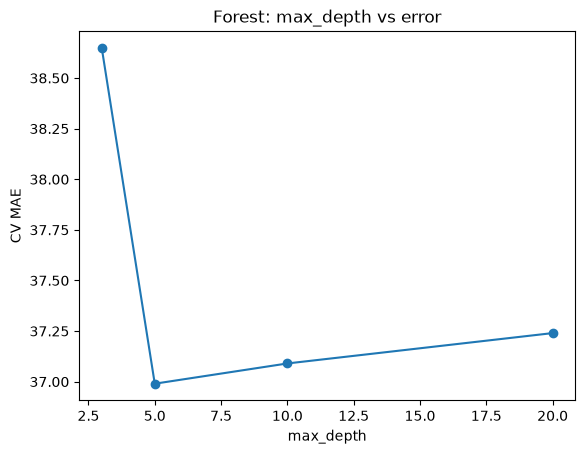

In [169]:
import matplotlib.pyplot as plt

depths = [3, 5, 10, 20]
maes = [38.65, 36.99, 37.09, 37.24]

plt.plot(depths, maes, marker='o')
plt.xlabel('max_depth')
plt.ylabel('CV MAE')
plt.title('Forest: max_depth vs error')
plt.show()

In [170]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict

forest = RandomForestRegressor(n_estimators=100, random_state=42)
pred = cross_val_predict(forest, x, y, cv=5)

results = df[['date', 'aqi_pm2.5']].copy()
results['pred'] = pred
results['error'] = results['pred'] - results['aqi_pm2.5']
results['abs_error'] = abs(results['error'])

print("Mean abs error:", round(results['abs_error'].mean(), 2))

Mean abs error: 37.18


In [171]:
worst = results.sort_values('abs_error', ascending=False).head(20)
print(worst)

           date  aqi_pm2.5    pred   error  abs_error
245  2020-02-01       34.0  375.12  341.12     341.12
246  2020-02-02       33.0  317.26  284.26     284.26
251  2020-02-07       33.0  307.24  274.24     274.24
250  2020-02-06       33.0  298.44  265.44     265.44
247  2020-02-03       33.0  294.64  261.64     261.64
253  2020-02-09       31.0  276.65  245.65     245.65
1307 2022-12-29      451.0  210.18 -240.82     240.82
1045 2022-04-11      404.0  173.73 -230.27     230.27
939  2021-12-26      500.0  269.87 -230.13     230.13
1267 2022-11-19       46.0  272.45  226.45     226.45
1270 2022-11-22       41.0  261.14  220.14     220.14
248  2020-02-04       38.0  258.10  220.10     220.10
252  2020-02-08       34.0  241.62  207.62     207.62
1316 2023-01-07      384.0  179.42 -204.58     204.58
254  2020-02-10       34.0  230.59  196.59     196.59
249  2020-02-05       33.0  224.26  191.26     191.26
945  2022-01-01      360.0  168.92 -191.08     191.08
1597 2023-10-15       93.0  

In [172]:
results['month'] = results['date'].dt.month
print(results.groupby('month')['abs_error'].mean().round(1))

results['year'] = results['date'].dt.year
print(results.groupby('year')['abs_error'].mean().round(1))

month
1     52.5
2     63.0
3     27.3
4     47.2
5     27.3
6     21.2
7     21.1
8     25.1
9     21.0
10    38.4
11    56.2
12    57.6
Name: abs_error, dtype: float64
year
2019    34.2
2020    43.4
2021    36.0
2022    39.6
2023    30.9
Name: abs_error, dtype: float64


In [173]:
low = results[results['aqi_pm2.5'] < 100]
mid = results[(results['aqi_pm2.5'] >= 100) & (results['aqi_pm2.5'] < 200)]
high = results[results['aqi_pm2.5'] >= 200]

print("Low  (under 100): days", len(low), " MAE", round(low['abs_error'].mean(), 1), " avg error", round(low['error'].mean(), 1))
print("Mid  (100-200):   days", len(mid), " MAE", round(mid['abs_error'].mean(), 1), " avg error", round(mid['error'].mean(), 1))
print("High (200+):      days", len(high), " MAE", round(high['abs_error'].mean(), 1), " avg error", round(high['error'].mean(), 1))

Low  (under 100): days 153  MAE 58.7  avg error 58.0
Mid  (100-200):   days 855  MAE 25.5  avg error 4.5
High (200+):      days 415  MAE 53.3  avg error -29.3


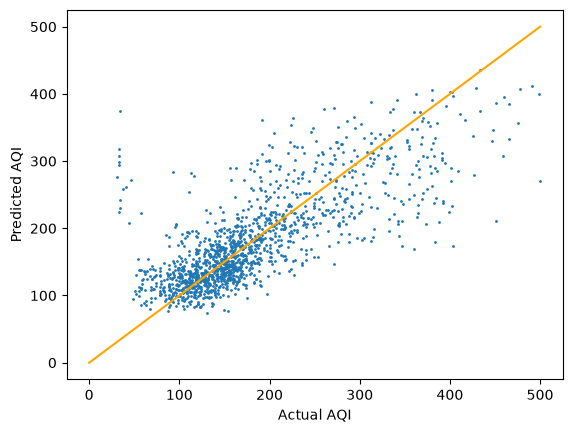

In [174]:
import matplotlib.pyplot as plt

plt.scatter(results['aqi_pm2.5'], results['pred'], s=1)
plt.plot([0, 500], [0, 500], color='orange')
plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.show()

In [175]:
df_sorted=df.sort_values('date').reset_index(drop=False)
x=df_sorted[features]
y=df_sorted['aqi_pm2.5']
forest=RandomForestRegressor(n_estimators=100,random_state=42)
pred=cross_val_predict(forest,x,y,cv=5)
model_errors=[]
copy_errors=[]
for i in range(1,len(df_sorted)):
    gap=(df_sorted['date'][i]-df_sorted['date'][i-1]).days
    if gap==1:
        actual=y[i]
        model_errors.append(abs(actual-pred[i]))
        copy_errors.append(abs(actual-y[i-1]))
print('Days compared:',len(model_errors))
print("model mae:",round(sum(model_errors)/len(model_errors),2))
print("copy mae:",round(sum(copy_errors)/len(copy_errors),2))


Days compared: 1391
model mae: 37.38
copy mae: 31.62
